## Summative Lab: Forest Fires Prevention

### Step 1: Load the Dataset

*   Install and import the ucimlrepo library.
*   Load the Forest Fires dataset:
 *   Predictors: Features from forest_fires.data.features.
 *   Target: forest_fires.data.targets.

In [1]:
# Run pip install if necessary (uncomment the next line), or use: pip install -r requirements.txt
# ! pip install ucimlrepo


In [2]:
# Data: load from the UCI repository, with the local CSV as an offline fallback
import pandas as pd

try:
    from ucimlrepo import fetch_ucirepo
    forest_fires = fetch_ucirepo(id=162)
    X = forest_fires.data.features
    y = forest_fires.data.targets
except Exception as err:
    print(f"Could not fetch from UCI ({type(err).__name__}); loading forestfires.csv instead.")
    raw = pd.read_csv('forestfires.csv')
    X = raw.drop(columns='area')
    y = raw[['area']]

# Display dataset structure
print(X.info())
print(X.describe())
print(y.head())


Could not fetch from UCI (ModuleNotFoundError); loading forestfires.csv instead.
<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
dtypes: float64(7), int64(3), str(2)
memory usage: 48.6 KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   


### Step 2: EDA

* Examine the dataset structure and summary statistics.
* Analyze correlations between predictors and the target variable.
* Plot scatterplots for key predictors vs. the target.
* Generate a residual plot to check for randomness in residuals.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# ── Combine features and target for exploration ──
df = X.copy()
df['area'] = y.values

print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nSummary statistics:")
df.describe()

Shape: (517, 13)

Missing values:
 X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

Summary statistics:


,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


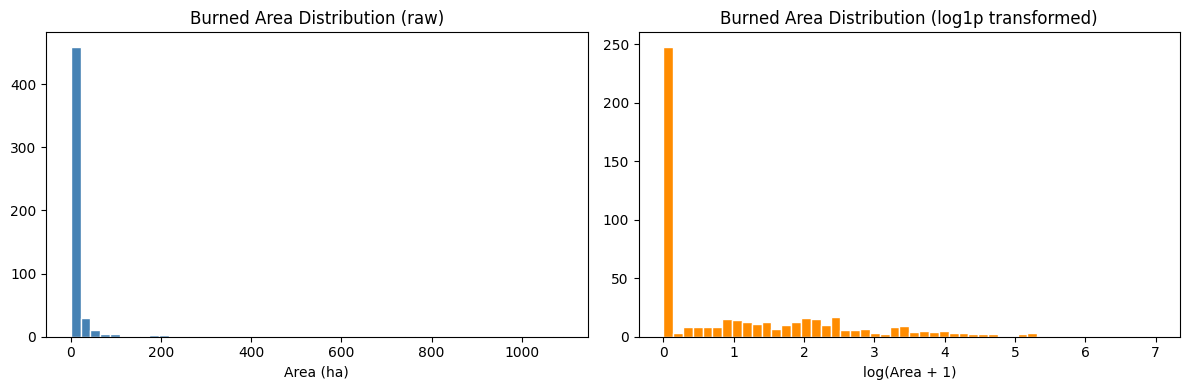

Skewness (raw):       12.85
Skewness (log1p):     1.22
Observations with area = 0: 247 / 517


In [4]:
# ── Target distribution (area is heavily right-skewed) ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['area'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Burned Area Distribution (raw)')
axes[0].set_xlabel('Area (ha)')

axes[1].hist(np.log1p(df['area']), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Burned Area Distribution (log1p transformed)')
axes[1].set_xlabel('log(Area + 1)')

plt.tight_layout()
plt.show()

print(f"Skewness (raw):       {df['area'].skew():.2f}")
print(f"Skewness (log1p):     {np.log1p(df['area']).skew():.2f}")
print(f"Observations with area = 0: {(df['area'] == 0).sum()} / {len(df)}")

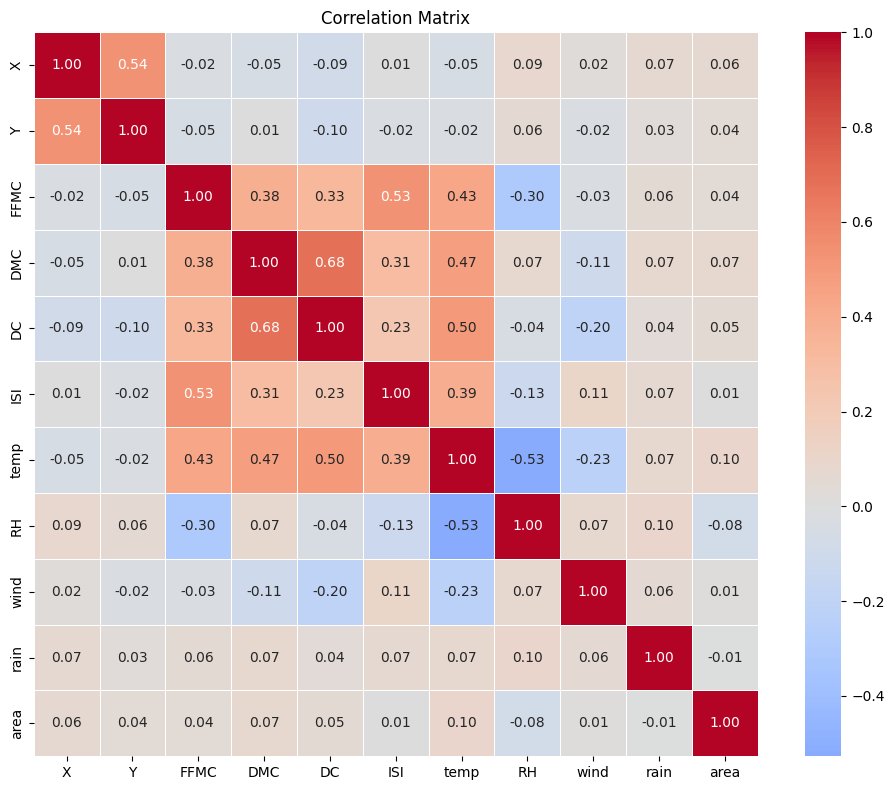

In [5]:
# ── Correlation heatmap (numeric features only) ──
numeric_cols = df.select_dtypes(include='number').columns.tolist()
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, square=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

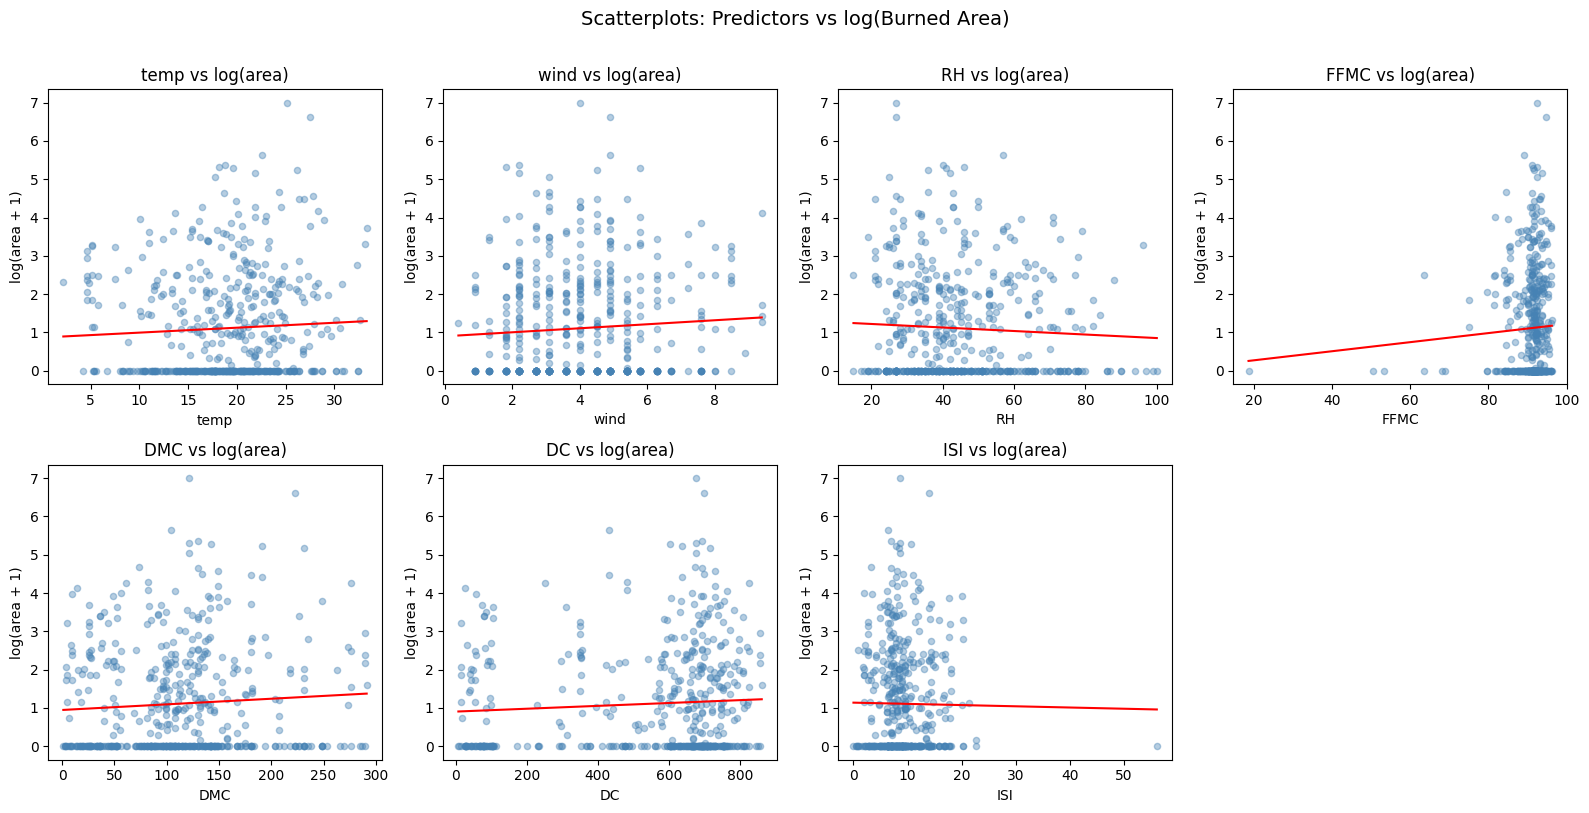

In [6]:
# ── Scatterplots: key continuous predictors vs log(area) ──
log_area = np.log1p(df['area'])
predictors = ['temp', 'wind', 'RH', 'FFMC', 'DMC', 'DC', 'ISI']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(predictors):
    axes[i].scatter(df[col], log_area, alpha=0.4, s=20, color='steelblue')
    # add a simple OLS trend line
    m, b = np.polyfit(df[col], log_area, 1)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    axes[i].plot(x_line, m * x_line + b, color='red', linewidth=1.5)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('log(area + 1)')
    axes[i].set_title(f'{col} vs log(area)')

axes[-1].set_visible(False)
plt.suptitle('Scatterplots: Predictors vs log(Burned Area)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

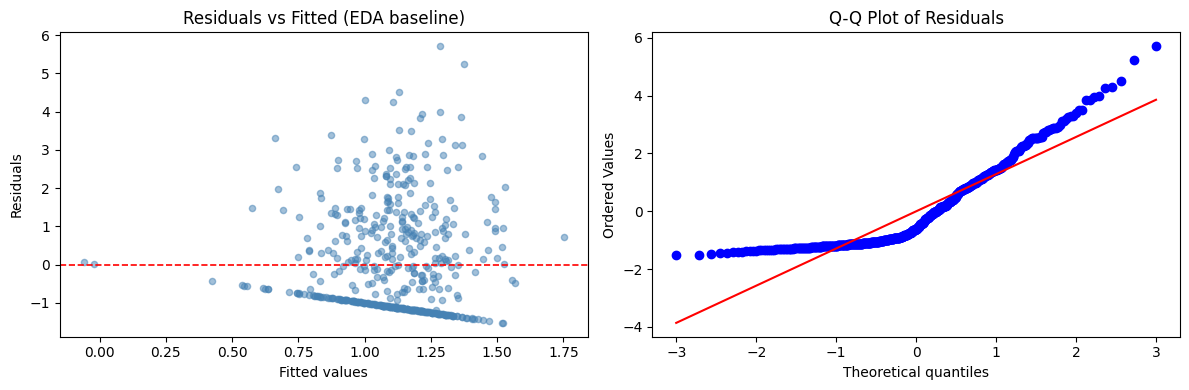

In [7]:
# ── Residual plot from a simple OLS baseline ──
from sklearn.linear_model import LinearRegression

numeric_feats = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
log_area = np.log1p(df['area'])

scaler_eda = StandardScaler()
X_eda = scaler_eda.fit_transform(df[numeric_feats])

lr_eda = LinearRegression()
lr_eda.fit(X_eda, log_area)
residuals_eda = log_area - lr_eda.predict(X_eda)
fitted_eda    = lr_eda.predict(X_eda)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted_eda, residuals_eda, alpha=0.5, color='steelblue', s=20)
axes[0].axhline(0, color='red', linewidth=1.2, linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (EDA baseline)')

import scipy.stats as stats
stats.probplot(residuals_eda, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

### Step 3: Fit the regression models

* Fit a baseline multiple linear regression model with key predictors.
* Include nonlinear terms (e.g., quadratic transformations for significant predictors).
* Add interaction terms (e.g., between predictors with strong correlations).
* Incorporate indicator variables if categorical variables are present.
* Apply transformations (e.g., logarithmic transformations for skewed predictors).

In [8]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Log-transform target (standard approach for this dataset)
df['log_area'] = np.log1p(df['area'])

# ── Encode categoricals ──
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
day_order   = ['mon','tue','wed','thu','fri','sat','sun']

df['month'] = pd.Categorical(df['month'], categories=month_order)
df['day']   = pd.Categorical(df['day'],   categories=day_order)

month_dummies = pd.get_dummies(df['month'], prefix='month', drop_first=True, dtype=float)
day_dummies   = pd.get_dummies(df['day'],   prefix='day',   drop_first=True, dtype=float)

# Numeric features
num_feats = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

# ── MODEL 1: Baseline (numeric only) ──
X1 = sm.add_constant(df[num_feats])
model1 = sm.OLS(df['log_area'], X1).fit()
print("MODEL 1 — Baseline (numeric features)")
print(model1.summary())

MODEL 1 — Baseline (numeric features)
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.288
Date:                Mon, 26 Oct 2026   Prob (F-statistic):              0.247
Time:                        21:19:19   Log-Likelihood:                -901.28
No. Observations:                 517   AIC:                             1821.
Df Residuals:                     508   BIC:                             1859.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         

In [9]:
# ── MODEL 2: With categorical indicator variables ──
X2 = pd.concat([df[num_feats], month_dummies, day_dummies], axis=1)
X2 = sm.add_constant(X2)
model2 = sm.OLS(df['log_area'], X2).fit()
print("MODEL 2 — With categorical (month & day) indicators")
print(model2.summary())

MODEL 2 — With categorical (month & day) indicators
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.068
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     1.442
Date:                Mon, 26 Oct 2026   Prob (F-statistic):             0.0778
Time:                        21:19:19   Log-Likelihood:                -888.15
No. Observations:                 517   AIC:                             1828.
Df Residuals:                     491   BIC:                             1939.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


In [10]:
# ── MODEL 3: Quadratic terms for temp and DMC ──
df['temp_sq'] = df['temp'] ** 2
df['DMC_sq']  = df['DMC']  ** 2

X3_cols = num_feats + ['temp_sq', 'DMC_sq']
X3 = sm.add_constant(df[X3_cols])
model3 = sm.OLS(df['log_area'], X3).fit()
print("MODEL 3 — Baseline + quadratic terms (temp², DMC²)")
print(model3.summary())

MODEL 3 — Baseline + quadratic terms (temp², DMC²)
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     2.135
Date:                Mon, 26 Oct 2026   Prob (F-statistic):             0.0205
Time:                        21:19:19   Log-Likelihood:                -895.78
No. Observations:                 517   AIC:                             1814.
Df Residuals:                     506   BIC:                             1860.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c

In [11]:
# ── MODEL 4: Interaction term (temp × wind) ──
df['temp_x_wind'] = df['temp'] * df['wind']
df['temp_x_RH']   = df['temp'] * df['RH']

X4_cols = num_feats + ['temp_sq', 'DMC_sq', 'temp_x_wind', 'temp_x_RH']
X4 = sm.add_constant(df[X4_cols])
model4 = sm.OLS(df['log_area'], X4).fit()
print("MODEL 4 — + interaction terms (temp×wind, temp×RH)")
print(model4.summary())

MODEL 4 — + interaction terms (temp×wind, temp×RH)
                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     2.032
Date:                Mon, 26 Oct 2026   Prob (F-statistic):             0.0201
Time:                        21:19:19   Log-Likelihood:                -894.26
No. Observations:                 517   AIC:                             1815.
Df Residuals:                     504   BIC:                             1870.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

### Step 4: Evaluate model diagnostics

* Compare models using metrics like R², adjusted R², AIC, and BIC.
* Plot residuals and create Q-Q plots to assess normality.
* Identify influential observations using Cook's Distance.

In [12]:
# ── Model comparison table ──
models = {
    'Model 1 (Baseline)':           model1,
    'Model 2 (+Categoricals)':      model2,
    'Model 3 (+Quadratics)':        model3,
    'Model 4 (+Interactions)':      model4,
}

comparison = pd.DataFrame({
    name: {
        'R²':          round(m.rsquared,      4),
        'Adj. R²':     round(m.rsquared_adj,  4),
        'AIC':         round(m.aic,            2),
        'BIC':         round(m.bic,            2),
        'F-stat':      round(m.fvalue,         2),
        'F p-value':   round(m.f_pvalue,       4),
        'Num. Params': int(m.df_model) + 1,
    }
    for name, m in models.items()
}).T

print(comparison.to_string())

                             R²  Adj. R²      AIC      BIC  F-stat  F p-value  Num. Params
Model 1 (Baseline)       0.0199   0.0044  1820.56  1858.79    1.29     0.2472          9.0
Model 2 (+Categoricals)  0.0684   0.0210  1828.30  1938.75    1.44     0.0778         26.0
Model 3 (+Quadratics)    0.0405   0.0215  1813.57  1860.30    2.14     0.0205         11.0
Model 4 (+Interactions)  0.0461   0.0234  1814.51  1869.74    2.03     0.0201         13.0


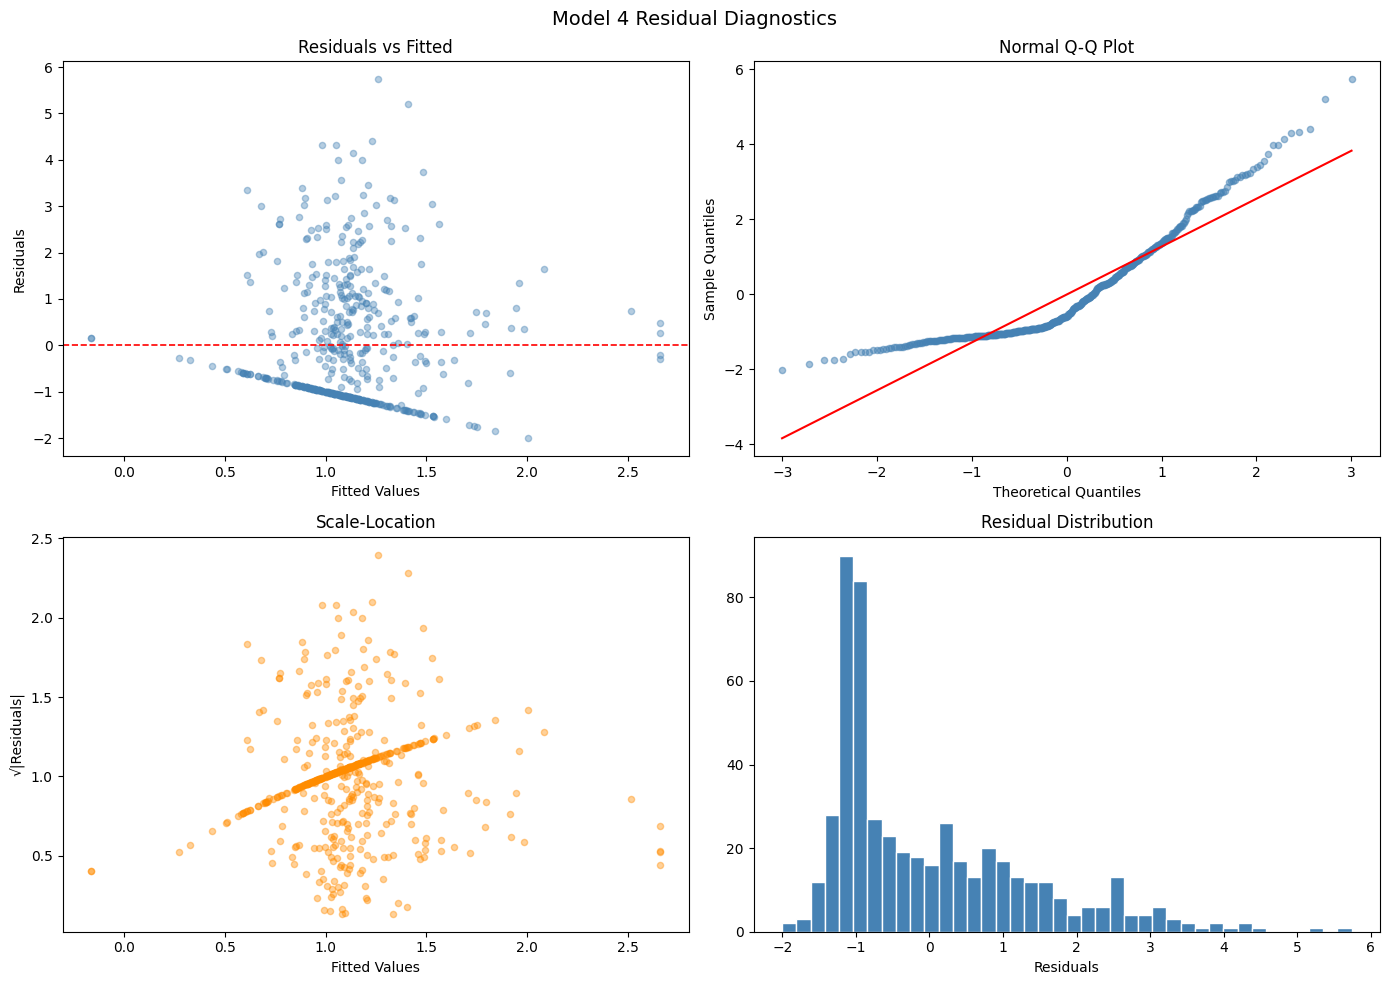


Omnibus test:   98.7886  p = 0.0000
Jarque-Bera:    155.1733  p = 0.0000
Skew:           1.2305
Kurtosis:       4.0707
Durbin-Watson:  0.9414


In [13]:
# ── Residual diagnostics for best model (Model 4) ──
best_model = model4

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Residuals vs Fitted
fitted    = best_model.fittedvalues
residuals = best_model.resid

axes[0,0].scatter(fitted, residuals, alpha=0.4, s=20, color='steelblue')
axes[0,0].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[0,0].set_xlabel('Fitted Values')
axes[0,0].set_ylabel('Residuals')
axes[0,0].set_title('Residuals vs Fitted')

# 2) Q-Q plot
import scipy.stats as stats
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[0,1].scatter(osm, osr, alpha=0.5, s=20, color='steelblue')
axes[0,1].plot(osm, slope * np.array(osm) + intercept, color='red', linewidth=1.5)
axes[0,1].set_xlabel('Theoretical Quantiles')
axes[0,1].set_ylabel('Sample Quantiles')
axes[0,1].set_title('Normal Q-Q Plot')

# 3) Scale-Location
sqrt_abs_res = np.sqrt(np.abs(residuals))
axes[1,0].scatter(fitted, sqrt_abs_res, alpha=0.4, s=20, color='darkorange')
axes[1,0].set_xlabel('Fitted Values')
axes[1,0].set_ylabel('√|Residuals|')
axes[1,0].set_title('Scale-Location')

# 4) Residual histogram
axes[1,1].hist(residuals, bins=40, color='steelblue', edgecolor='white')
axes[1,1].set_xlabel('Residuals')
axes[1,1].set_title('Residual Distribution')

plt.suptitle("Model 4 Residual Diagnostics", fontsize=14)
plt.tight_layout()
plt.show()

# OLS normality test stats (use stattools directly — diagn is RLM-only)
from statsmodels.stats.stattools import omni_normtest, jarque_bera, durbin_watson
from scipy.stats import skew, kurtosis

omni_stat, omni_p = omni_normtest(residuals)
jb_stat, jb_p, jb_skew, jb_kurt = jarque_bera(residuals)
dw = durbin_watson(residuals)

print(f"\nOmnibus test:   {omni_stat:.4f}  p = {omni_p:.4f}")
print(f"Jarque-Bera:    {jb_stat:.4f}  p = {jb_p:.4f}")
print(f"Skew:           {skew(residuals):.4f}")
print(f"Kurtosis:       {kurtosis(residuals, fisher=False):.4f}")
print(f"Durbin-Watson:  {dw:.4f}")

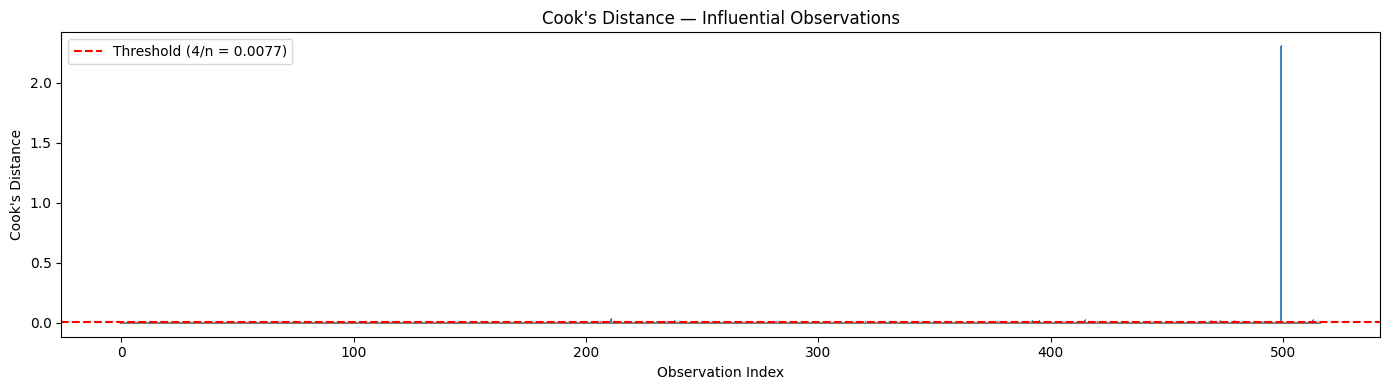

Influential observations (Cook's D > 4/n): 20


In [14]:
# ── Cook's Distance ──
from statsmodels.stats.outliers_influence import OLSInfluence

influence = OLSInfluence(best_model)
cooks_d, _ = influence.cooks_distance

fig, ax = plt.subplots(figsize=(14, 4))
ax.stem(range(len(cooks_d)), cooks_d, markerfmt=',', linefmt='steelblue',
        basefmt='grey')
threshold = 4 / len(df)
ax.axhline(threshold, color='red', linestyle='--', label=f"Threshold (4/n = {threshold:.4f})")
ax.set_xlabel('Observation Index')
ax.set_ylabel("Cook's Distance")
ax.set_title("Cook's Distance — Influential Observations")
ax.legend()
plt.tight_layout()
plt.show()

n_influential = (cooks_d > threshold).sum()
print(f"Influential observations (Cook's D > 4/n): {n_influential}")

### Step 5: Apply regularization

* Use Ridge (L2) and Lasso (L1) regression from sklearn to handle multicollinearity.
* Extract coefficients and calculate Mean Squared Error (MSE).
* Compare the performance of Ridge and Lasso models.

In [15]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler

# -- Build feature matrix for regularized models --
X_reg_df = pd.concat([df[num_feats], month_dummies, day_dummies,
                       df[['temp_sq', 'DMC_sq', 'temp_x_wind', 'temp_x_RH']]], axis=1)
y_reg = df['log_area'].values

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# -- Hyperparameter search: alpha grid --
# Scaling is done inside each CV fold (pipeline) so the held-out fold never influences the scaler.
alphas = [0.001, 0.01, 0.1, 1, 5, 10, 50, 100, 500, 1000]

results = {}
for alpha in alphas:
    for name, model in [('Ridge', Ridge(alpha=alpha)),
                        ('Lasso', Lasso(alpha=alpha, max_iter=10000)),
                        ('ElasticNet', ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000))]:
        pipe = make_pipeline(StandardScaler(), model)
        cv_mse = -cross_val_score(pipe, X_reg_df, y_reg,
                                  scoring='neg_mean_squared_error', cv=kf).mean()
        results[(name, alpha)] = cv_mse

# -- Reference point: a model that always predicts the mean of log(area + 1) --
baseline_mse = -cross_val_score(DummyRegressor(strategy='mean'), X_reg_df, y_reg,
                                scoring='neg_mean_squared_error', cv=kf).mean()
print(f"Mean-only baseline: CV MSE = {baseline_mse:.4f}\n")

# -- Best alpha per model type (stored for the final fits below) --
best_alphas = {}
for model_name in ['Ridge', 'Lasso', 'ElasticNet']:
    sub = {k: v for k, v in results.items() if k[0] == model_name}
    best_key = min(sub, key=sub.get)
    best_alphas[model_name] = best_key[1]
    edge = "  (edge of the alpha grid)" if best_key[1] in (min(alphas), max(alphas)) else ""
    print(f"{model_name}: best alpha = {best_key[1]}, CV MSE = {sub[best_key]:.4f}{edge}")


Mean-only baseline: CV MSE = 1.9541

Ridge: best alpha = 1000, CV MSE = 1.9544  (edge of the alpha grid)
Lasso: best alpha = 0.1, CV MSE = 1.9282
ElasticNet: best alpha = 0.1, CV MSE = 1.9431


In [16]:
# -- Fit final regularized models with the CV-selected alphas --
scaler = StandardScaler()
X_reg  = scaler.fit_transform(X_reg_df)

best_ridge = Ridge(alpha=best_alphas['Ridge'])
best_lasso = Lasso(alpha=best_alphas['Lasso'], max_iter=10000)
best_enet  = ElasticNet(alpha=best_alphas['ElasticNet'], l1_ratio=0.5, max_iter=10000)

for name, model in [('Ridge', best_ridge), ('Lasso', best_lasso), ('ElasticNet', best_enet)]:
    model.fit(X_reg, y_reg)
    preds  = model.predict(X_reg)
    mse    = mean_squared_error(y_reg, preds)
    r2     = r2_score(y_reg, preds)
    n_zero = np.sum(np.abs(model.coef_) < 1e-6)
    print(f"{name:12s} | alpha = {best_alphas[name]:<6} | Train R² = {r2:.4f} | Train MSE = {mse:.4f} | Zeroed coefs = {n_zero}")


Ridge        | alpha = 1000   | Train R² = 0.0362 | Train MSE = 1.8812 | Zeroed coefs = 0
Lasso        | alpha = 0.1    | Train R² = 0.0225 | Train MSE = 1.9079 | Zeroed coefs = 26
ElasticNet   | alpha = 0.1    | Train R² = 0.0412 | Train MSE = 1.8713 | Zeroed coefs = 19


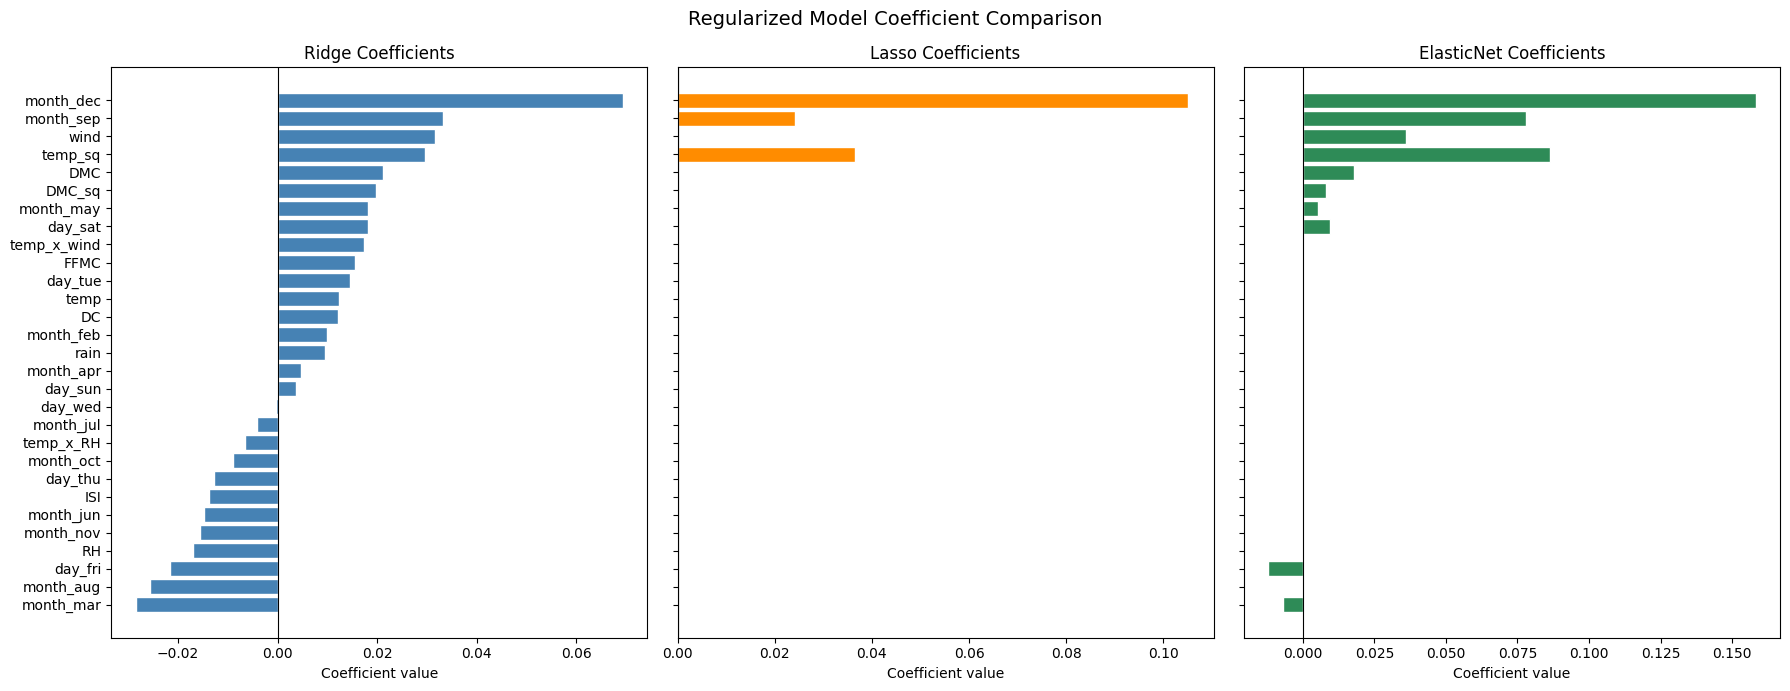

In [17]:
# ── Coefficient comparison plot ──
feature_names = list(X_reg_df.columns)

coef_df = pd.DataFrame({
    'Feature':    feature_names,
    'Ridge':      best_ridge.coef_,
    'Lasso':      best_lasso.coef_,
    'ElasticNet': best_enet.coef_,
})
coef_df = coef_df.set_index('Feature')

fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
colors = {'Ridge': 'steelblue', 'Lasso': 'darkorange', 'ElasticNet': 'seagreen'}

for ax, col in zip(axes, ['Ridge', 'Lasso', 'ElasticNet']):
    vals = coef_df[col].sort_values()
    bars = ax.barh(vals.index, vals.values, color=colors[col], edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{col} Coefficients')
    ax.set_xlabel('Coefficient value')

plt.suptitle('Regularized Model Coefficient Comparison', fontsize=14)
plt.tight_layout()
plt.show()

### Step 6: Prepare the data for binary classification

* Create a binary target variable based on a threshold in y (e.g., median or other percentile).
* Select relevant predictors and scale them using StandardScaler.

In [18]:
from sklearn.model_selection import train_test_split

# ── Binary target: 1 if area > median (excluding zeros), 0 otherwise ──
# Median of non-zero areas gives a meaningful "large fire" threshold
nonzero_median = df.loc[df['area'] > 0, 'area'].median()
print(f"Non-zero median burned area: {nonzero_median:.2f} ha")

threshold = nonzero_median
df['large_fire'] = (df['area'] > threshold).astype(int)
print(f"\nClass distribution:")
print(df['large_fire'].value_counts(normalize=True).round(3))

# ── Feature selection for classification ──
clf_feats = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

X_clf = df[clf_feats].copy()
y_clf = df['large_fire'].values

# -- Train / test split (before scaling, so the test set cannot influence the scaler) --
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

scaler_clf = StandardScaler().fit(X_train_raw)
X_train = pd.DataFrame(scaler_clf.transform(X_train_raw), columns=clf_feats, index=X_train_raw.index)
X_test  = pd.DataFrame(scaler_clf.transform(X_test_raw),  columns=clf_feats, index=X_test_raw.index)

print(f"\nTraining set: {X_train.shape[0]} observations")
print(f"Test set:     {X_test.shape[0]} observations")


Non-zero median burned area: 6.37 ha

Class distribution:
large_fire
0    0.739
1    0.261
Name: proportion, dtype: float64

Training set: 413 observations
Test set:     104 observations


### Step 7: Train and evaluate a logistic regression model

Train a logistic regression model using the scaled predictors.

* Display coefficients and the intercept.
* Predict probabilities and binary outcomes.
* Evaluate performance using accuracy, confusion matrix, precision, recall, and F1-score.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                              classification_report, roc_auc_score,
                              RocCurveDisplay)

# ── Train logistic regression ──
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# ── Coefficients ──
coef_series = pd.Series(log_reg.coef_[0], index=clf_feats)
print("Intercept:", round(log_reg.intercept_[0], 4))
print("\nCoefficients (log-odds):")
print(coef_series.sort_values(ascending=False).round(4))

Intercept: -1.055

Coefficients (log-odds):
rain    0.1494
DMC     0.0965
DC      0.0656
wind    0.0531
FFMC    0.0216
ISI    -0.0201
temp   -0.1899
RH     -0.3197
dtype: float64


In [20]:
# ── Predictions & evaluation ──
y_pred      = log_reg.predict(X_test)
y_prob      = log_reg.predict_proba(X_test)[:, 1]

acc  = accuracy_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {acc:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Small fire', 'Large fire'], zero_division=0))

Accuracy:  0.7404
ROC-AUC:   0.4808

Classification Report:
              precision    recall  f1-score   support

  Small fire       0.74      1.00      0.85        77
  Large fire       0.00      0.00      0.00        27

    accuracy                           0.74       104
   macro avg       0.37      0.50      0.43       104
weighted avg       0.55      0.74      0.63       104



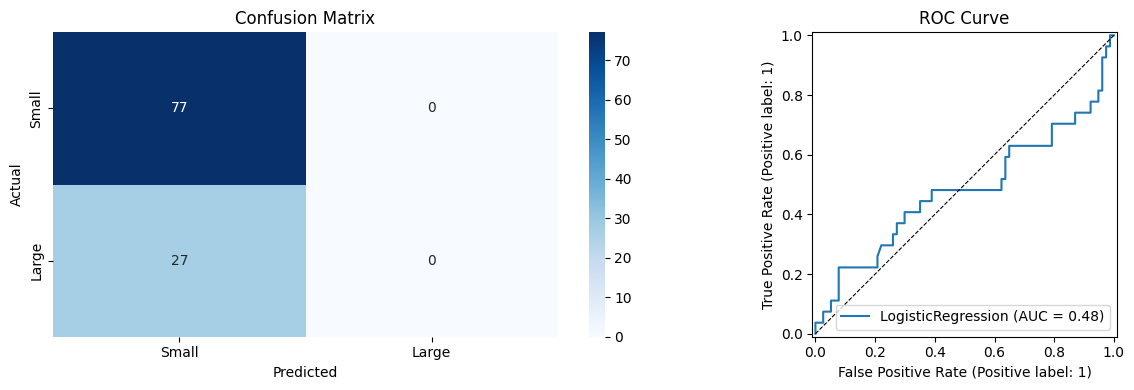

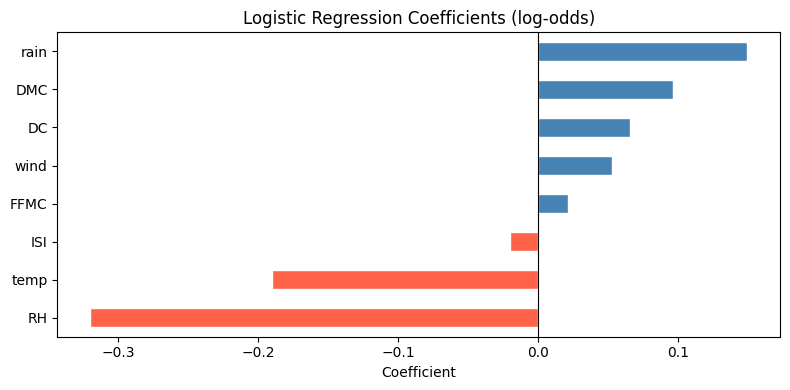

In [21]:
# ── Confusion matrix ──
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Small', 'Large'],
            yticklabels=['Small', 'Large'], ax=axes[0])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')

# ── ROC Curve ──
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=axes[1])
axes[1].plot([0,1],[0,1], 'k--', linewidth=0.8)
axes[1].set_title('ROC Curve')

plt.tight_layout()
plt.show()

# ── Coefficient visualization ──
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['steelblue' if v > 0 else 'tomato' for v in coef_series.sort_values()]
coef_series.sort_values().plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression Coefficients (log-odds)')
ax.set_xlabel('Coefficient')
plt.tight_layout()
plt.show()

### Step 8: Check assumptions

* Use Variance Inflation Factor (VIF) to assess multicollinearity among predictors.

VIF Results (multicollinearity check):
Feature  VIF
   temp 2.66
    DMC 2.33
     DC 2.08
     RH 1.90
   FFMC 1.70
    ISI 1.58
   wind 1.14
   rain 1.04

Interpretation guide:
  VIF < 5   → Low multicollinearity (acceptable)
  5 ≤ VIF < 10 → Moderate (monitor)
  VIF ≥ 10  → High multicollinearity (problematic)


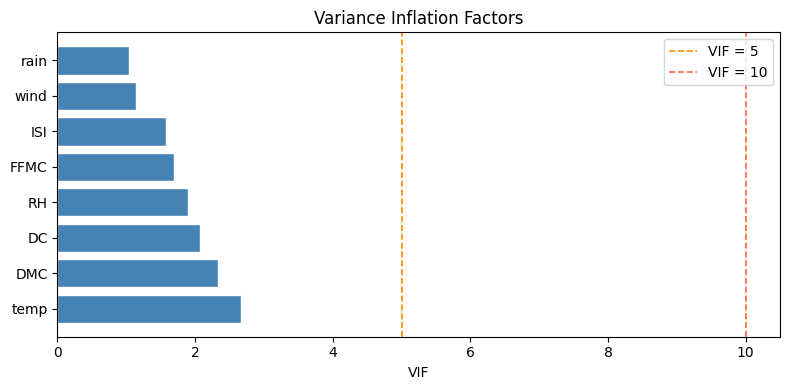

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ── VIF for classification predictors ──
X_vif = sm.add_constant(df[clf_feats])
vif_data = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF':     [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data = vif_data[vif_data['Feature'] != 'const'].sort_values('VIF', ascending=False)

print("VIF Results (multicollinearity check):")
print(vif_data.round(2).to_string(index=False))
print()
print("Interpretation guide:")
print("  VIF < 5   → Low multicollinearity (acceptable)")
print("  5 ≤ VIF < 10 → Moderate (monitor)")
print("  VIF ≥ 10  → High multicollinearity (problematic)")

# ── VIF bar chart ──
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['tomato' if v >= 10 else 'darkorange' if v >= 5 else 'steelblue'
          for v in vif_data['VIF']]
ax.barh(vif_data['Feature'], vif_data['VIF'], color=colors, edgecolor='white')
ax.axvline(5,  color='darkorange', linestyle='--', linewidth=1.2, label='VIF = 5')
ax.axvline(10, color='tomato',     linestyle='--', linewidth=1.2, label='VIF = 10')
ax.set_xlabel('VIF')
ax.set_title('Variance Inflation Factors')
ax.legend()
plt.tight_layout()
plt.show()

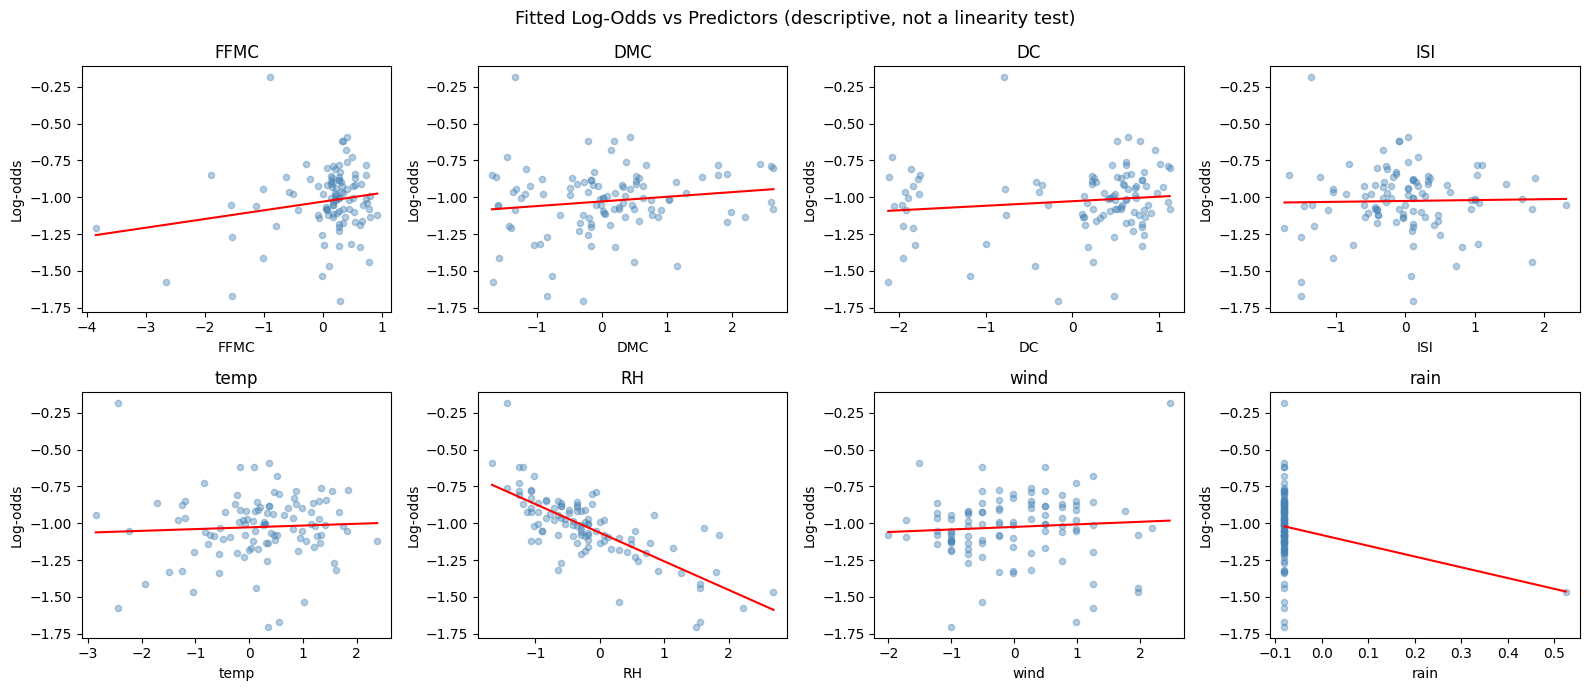

In [23]:
# ── Fitted log-odds vs each predictor (descriptive only: fitted log-odds are linear in the predictors by construction) ──
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

log_odds = np.log(y_prob + 1e-6) - np.log(1 - y_prob + 1e-6)

for i, feat in enumerate(clf_feats):
    axes[i].scatter(X_test[feat], log_odds, alpha=0.4, s=20, color='steelblue')
    m, b = np.polyfit(X_test[feat], log_odds, 1)
    x_line = np.linspace(X_test[feat].min(), X_test[feat].max(), 100)
    axes[i].plot(x_line, m * x_line + b, color='red', linewidth=1.5)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Log-odds')
    axes[i].set_title(f'{feat}')

plt.suptitle('Fitted Log-Odds vs Predictors (descriptive, not a linearity test)', fontsize=13)
plt.tight_layout()
plt.show()

### Step 9: Summative Findings

* Compare regression models and classification results.
* Highlight trade-offs between model simplicity, performance, and interpretability.
* Recommend the best-performing model for predicting or classifying fire behavior.

In [24]:
# ── Final summary table: Regression models ──
print("=" * 65)
print("REGRESSION MODEL COMPARISON")
print("=" * 65)
print(comparison.to_string())
print()

# ── Regularization comparison ──
print("=" * 65)
print("REGULARIZATION COMPARISON (Train metrics on full engineered features)")
print("=" * 65)

reg_summary = []
for name, model, alpha in [('Ridge',      best_ridge, best_alphas['Ridge']),
                            ('Lasso',      best_lasso, best_alphas['Lasso']),
                            ('ElasticNet', best_enet,  best_alphas['ElasticNet'])]:
    preds = model.predict(X_reg)
    reg_summary.append({
        'Model':       name,
        'Alpha':       alpha,
        'Train R²':    round(r2_score(y_reg, preds), 4),
        'Train MSE':   round(mean_squared_error(y_reg, preds), 4),
        'Non-zero coef': int(np.sum(np.abs(model.coef_) > 1e-6)),
    })

print(pd.DataFrame(reg_summary).set_index('Model').to_string())
print()

# ── Classification summary ──
print("=" * 65)
print("LOGISTIC REGRESSION CLASSIFICATION")
print("=" * 65)
print(f"  Accuracy : {acc:.4f}")
print(f"  ROC-AUC  : {auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['Small fire', 'Large fire'], zero_division=0))

REGRESSION MODEL COMPARISON
                             R²  Adj. R²      AIC      BIC  F-stat  F p-value  Num. Params
Model 1 (Baseline)       0.0199   0.0044  1820.56  1858.79    1.29     0.2472          9.0
Model 2 (+Categoricals)  0.0684   0.0210  1828.30  1938.75    1.44     0.0778         26.0
Model 3 (+Quadratics)    0.0405   0.0215  1813.57  1860.30    2.14     0.0205         11.0
Model 4 (+Interactions)  0.0461   0.0234  1814.51  1869.74    2.03     0.0201         13.0

REGULARIZATION COMPARISON (Train metrics on full engineered features)
             Alpha  Train R²  Train MSE  Non-zero coef
Model                                                 
Ridge       1000.0    0.0362     1.8812             29
Lasso          0.1    0.0225     1.9079              3
ElasticNet     0.1    0.0412     1.8713             10

LOGISTIC REGRESSION CLASSIFICATION
  Accuracy : 0.7404
  ROC-AUC  : 0.4808

              precision    recall  f1-score   support

  Small fire       0.74      1.00      

### Summative Findings

**Dataset context**

The Forest Fires dataset (517 observations, 12 features) contains meteorological and FWI (Fire Weather Index) variables recorded in Montesinho Park, Portugal. The target variable `area` (burned area in hectares) is extremely right-skewed (skewness 12.85), and 247 observations (48%) report zero burned area. A `log(area + 1)` transformation was used for all regression work and reduces skewness to 1.22.

---

**Regression results**

| Model | R² | Adj. R² | AIC | BIC | F-test p-value |
|---|---|---|---|---|---|
| Model 1: baseline (8 numeric features) | 0.0199 | 0.0044 | 1820.56 | 1858.79 | 0.2472 |
| Model 2: + month and day indicators | 0.0684 | 0.0210 | 1828.30 | 1938.75 | 0.0778 |
| Model 3: + quadratic terms (temp², DMC²) | 0.0405 | 0.0215 | 1813.57 | 1860.30 | 0.0205 |
| Model 4: + interactions (temp × wind, temp × RH) | 0.0461 | 0.0234 | 1814.51 | 1869.74 | 0.0201 |

No model explains more than 7% of the variation in log burned area, and the best adjusted R² is 0.023. The selection criteria disagree: AIC prefers Model 3, BIC prefers Model 1 and adjusted R² prefers Model 4. Models 3 and 4 are almost indistinguishable (AIC differs by about 1), so Model 4 is not clearly "best", only the most flexible. When the criteria split like this, it usually means no model has found a strong signal.

**Key regression insights:**
- Model 1 does not pass its overall F-test (p = 0.247). Models 3 and 4 pass it at the 5% level (p ≈ 0.02), but with R² under 0.05 the effect is statistically detectable and practically tiny.
- At the individual level, only `temp` and `temp²` are significant in Models 3 and 4 (p < 0.05). `DMC`, `DMC²`, `temp × wind` and `temp × RH` are not significant. In Model 1 only `wind` is significant (p = 0.039).
- The quadratic temperature term gives a U-shaped fit with its minimum near 18.6 °C, so predicted log burned area is higher at both cooler and hotter temperatures. With few observations at the extremes, this should be read cautiously and not as proof that temperature drives fire size.
- Model 2 has the highest R² (0.068) but the worst AIC and BIC, because the 17 month and day indicators add parameters without adding real explanatory power.
- Model 4 residuals are right-skewed (skew 1.23) and heavy-tailed (kurtosis 4.07), and normality is rejected (p < 0.001). The Durbin-Watson statistic of 0.94 points to positive residual autocorrelation, and 20 observations exceed the Cook's distance threshold of 4/n. The p-values above are therefore approximate.

---

**Regularization results**

| Model | Best alpha | 5-fold CV MSE | Non-zero coefficients (final fit) |
|---|---|---|---|
| Mean-only baseline | n/a | 1.9541 | n/a |
| Ridge (L2) | 1000 (edge of grid) | 1.9544 | 29 of 29 |
| Lasso (L1) | 0.1 | 1.9282 | 3 of 29 |
| ElasticNet (l1 ratio 0.5) | 0.1 | 1.9431 | 10 of 29 |

Scaling was done inside each cross-validation fold so the held-out fold never influenced the scaler. Ridge's best alpha was the largest value tried, and at that level it simply reproduces the mean-only baseline, so Ridge never beat a model that always predicts the average. Lasso did best, but only about 1.3% below the baseline, and ElasticNet about 0.6% below. The final-fit train R² values (0.02 to 0.04) are in-sample and optimistic. Overall, regularization did not reveal a usable predictive signal.

---

**Classification results**

Binarising `area` at the non-zero median (6.37 ha) labels 26% of fires as "large". On the 104-observation test set, logistic regression reached **74.0% accuracy** and a **ROC-AUC of 0.481**. That accuracy is misleading: the model predicted "small" for every test case, which is exactly what a majority-class guess scores (77 of 104). Recall and precision for large fires are both 0, and an AUC below 0.5 means the predicted probabilities ranked fires no better than chance.

- All coefficients are small (the largest is `RH` at about -0.32), consistent with a model that has found no real signal.
- VIF values are all below 2.7, so multicollinearity is not the problem.
- The log-odds plot shows the model's fitted log-odds against each predictor. Because fitted log-odds are linear in the predictors by construction, this plot cannot test the linearity assumption. A Box-Tidwell test or binned empirical logits would be needed for that.

---

**Recommendation**

| Task | Takeaway |
|---|---|
| Predicting burned area (regression) | No model here is good enough to deploy. If one must be chosen, Lasso has the best cross-validated error and the sparsest fit, but only marginally beats a mean-only prediction. |
| Classifying fire size | The logistic regression as fitted is not usable. Its accuracy equals the majority-class rate and it never identifies a large fire. |
| Feature selection | Lasso kept only 3 of 29 features, which reinforces that few inputs carry signal. |

The weak results reflect a known difficulty with this dataset: fire size is hard to predict from weather snapshots alone. Reasonable next steps are:
- Use the spatial coordinates `X` and `Y`, which were left out of every model.
- Address class imbalance with `class_weight="balanced"`, tune the decision threshold, and evaluate with precision-recall curves.
- Try tree-based models that can capture non-linear thresholds.
- Model zero-area and positive-area fires in two stages.
- Use time-aware validation, given the residual autocorrelation.